# Data Preprocessing Pipeline
## CNN-LSTM Binary Classification - Student Answer Scripts

### Step 1 - Imports

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from scipy.ndimage import rotate

### Step 2 - Dataset structure verification
Checks that every student has exactly 15 pages.

In [2]:
dataset_root = "../data/labeled/by_exercise"

total_correct = 0
total_incorrect = 0

for q_dir in sorted(os.listdir(dataset_root)):
    q_path = os.path.join(dataset_root, q_dir)
    if not os.path.isdir(q_path):
        continue
    correct = len(os.listdir(os.path.join(q_path, "correct"))) if os.path.isdir(os.path.join(q_path, "correct")) else 0
    incorrect = len(os.listdir(os.path.join(q_path, "incorrect"))) if os.path.isdir(os.path.join(q_path, "incorrect")) else 0
    total_correct += correct
    total_incorrect += incorrect
    print(f"  {q_dir}: {correct} correct, {incorrect} incorrect")

print(f"\nTotal: {total_correct} correct, {total_incorrect} incorrect, {total_correct + total_incorrect} images")

  q01: 4 correct, 1 incorrect
  q02: 4 correct, 1 incorrect
  q03: 5 correct, 0 incorrect
  q07: 4 correct, 1 incorrect
  q08: 4 correct, 1 incorrect
  q09: 4 correct, 1 incorrect
  q10: 4 correct, 1 incorrect
  q11: 4 correct, 1 incorrect
  q12: 3 correct, 2 incorrect
  q13: 3 correct, 2 incorrect
  q14: 3 correct, 2 incorrect
  q15: 4 correct, 1 incorrect
  q16: 4 correct, 1 incorrect
  q17: 4 correct, 1 incorrect
  q18: 3 correct, 2 incorrect
  q19: 4 correct, 1 incorrect
  q20: 4 correct, 1 incorrect
  q21: 4 correct, 1 incorrect
  q22: 3 correct, 2 incorrect
  q23: 4 correct, 1 incorrect
  q24: 3 correct, 2 incorrect
  q25: 3 correct, 2 incorrect
  q26: 2 correct, 3 incorrect
  q27: 2 correct, 3 incorrect
  q28: 4 correct, 1 incorrect
  q29: 3 correct, 2 incorrect
  q30: 3 correct, 2 incorrect

Total: 96 correct, 39 incorrect, 135 images


### Step 3 - Visualize a raw image
Original scan before any preprocessing.

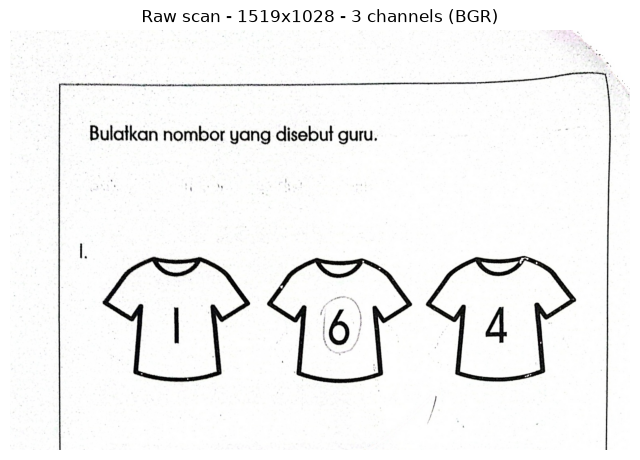

Shape: (1028, 1519, 3)
Dtype: uint8
Min: 0, Max: 255


In [3]:
sample_path = "../data/labeled/by_exercise/q01/correct/set_2_q01.jpg"

original = cv2.imread(sample_path)
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 11))
plt.imshow(original_rgb)
plt.title(f"Raw scan - {original.shape[1]}x{original.shape[0]} - 3 channels (BGR)")
plt.axis('off')
plt.show()

print(f"Shape: {original.shape}")
print(f"Dtype: {original.dtype}")
print(f"Min: {original.min()}, Max: {original.max()}")

### Step 4 - Grayscale conversion
Convert from 3 color channels (RGB) to 1 grayscale channel. Student answer scripts are black and white scans, color adds no useful information and triples the data size.

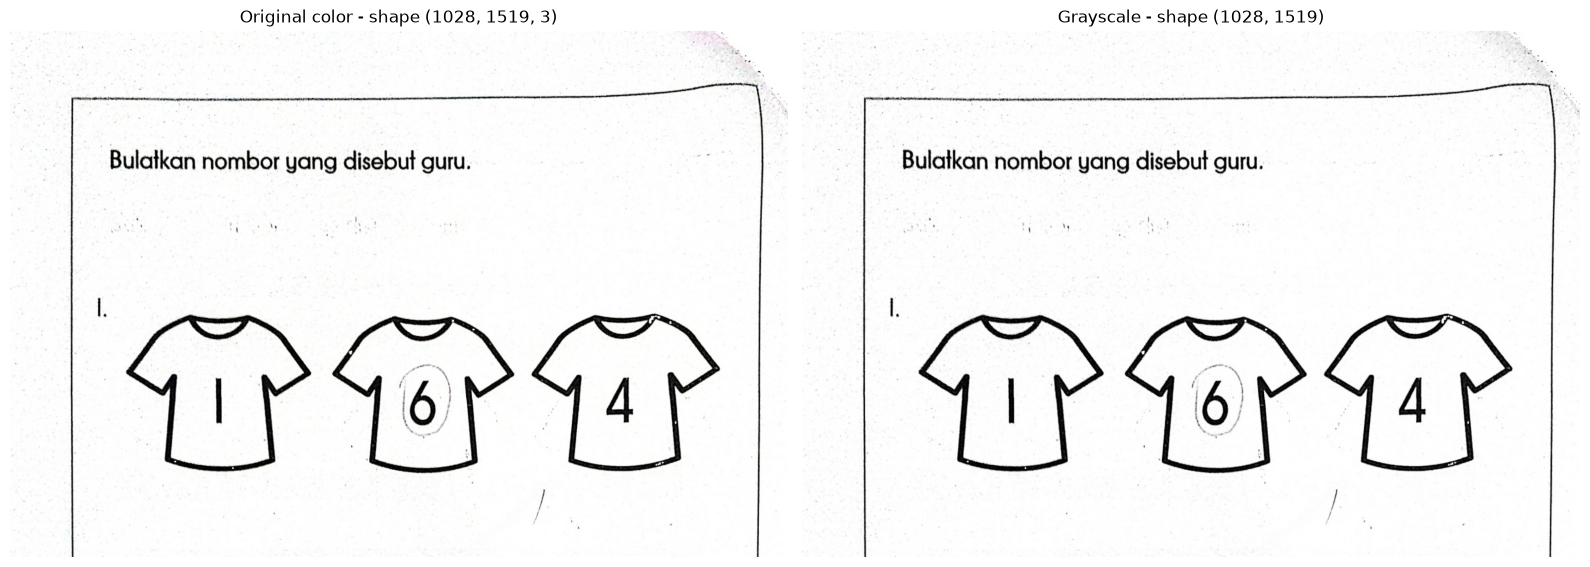

Color channels: 3 → 1
Pixel values: 0 to 255


In [4]:
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(original_rgb)
axes[0].set_title(f"Original color - shape {original.shape}")
axes[1].imshow(gray, cmap='gray')
axes[1].set_title(f"Grayscale - shape {gray.shape}")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Color channels: {original.shape[2]} → 1")
print(f"Pixel values: {gray.min()} to {gray.max()}")

### Step 5 - Resize to 224x224
Pre-trained CNNs (ResNet, EfficientNet, etc.) expect 224x224 input. This is the standard ImageNet size used during their training.

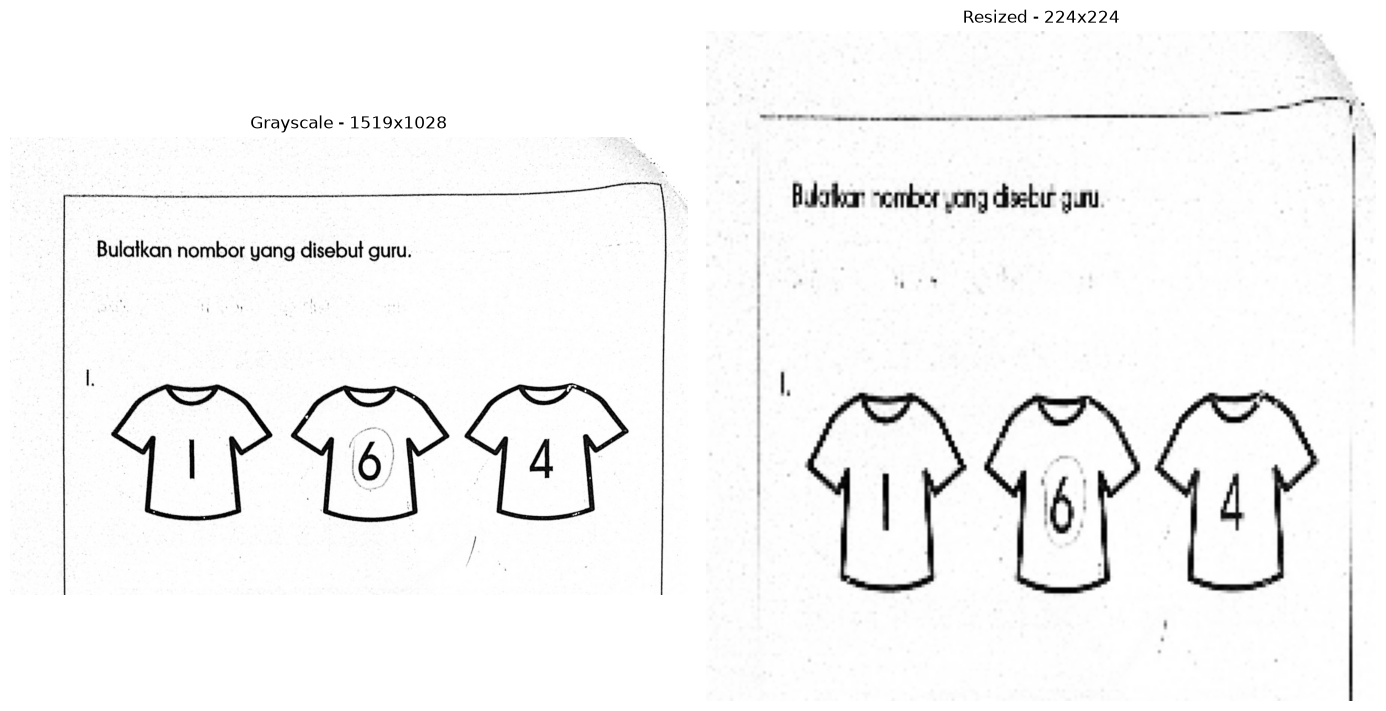

Before: (1028, 1519) → After: (224, 224)


In [5]:
resized = cv2.resize(gray, (224, 224))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title(f"Grayscale - {gray.shape[1]}x{gray.shape[0]}")
axes[1].imshow(resized, cmap='gray')
axes[1].set_title(f"Resized - {resized.shape[1]}x{resized.shape[0]}")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Before: {gray.shape} → After: {resized.shape}")

### Step 6 - ImageNet Normalization
Normalize using ImageNet mean and std, required for transfer learning with pre-trained CNNs.

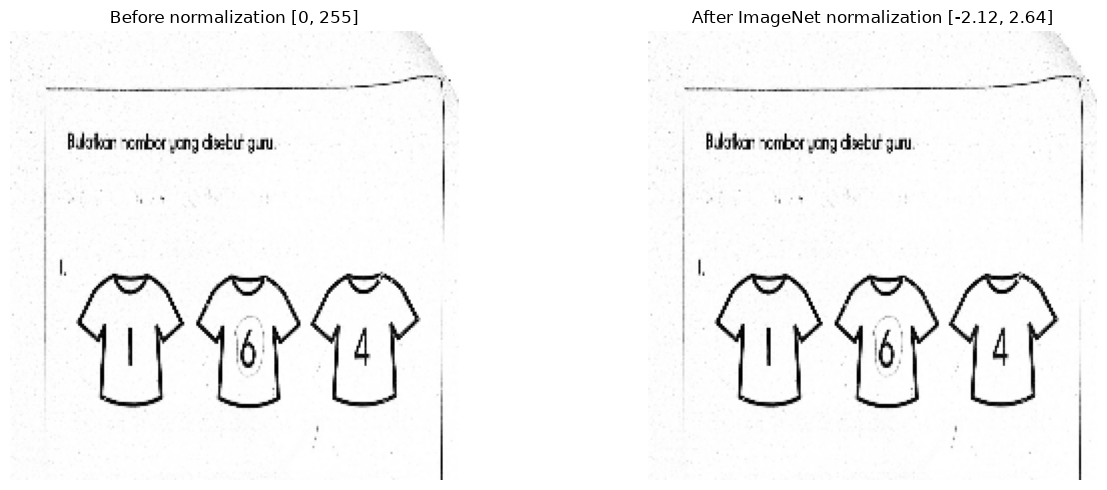

Shape: (224, 224) → (224, 224, 3)
Before: min=0, max=255 (integers)
After: min=-2.1179, max=2.6400 (floats)


In [6]:
# Réplication 3 canaux
rgb = np.stack([resized, resized, resized], axis=-1)

# Normalisation ImageNet
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
normalized = (rgb / 255.0 - mean) / std

def denormalize_for_display(img):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    denorm = img * std + mean
    return np.clip(denorm, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(resized, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f"Before normalization [0, 255]")
axes[1].imshow(denormalize_for_display(normalized))
axes[1].set_title(f"After ImageNet normalization [{normalized.min():.2f}, {normalized.max():.2f}]")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"Shape: {resized.shape} → {normalized.shape}")
print(f"Before: min={resized.min()}, max={resized.max()} (integers)")
print(f"After: min={normalized.min():.4f}, max={normalized.max():.4f} (floats)")

### Step 7 - Full preprocessing function
Combines grayscale + resize + 3-channel replication + ImageNet normalization into one function.

In [7]:
def preprocess_page(image_path, target_size=(224, 224)):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Impossible de lire {image_path}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, target_size)

    # Repeat grayscale to 3 channels for transfer learning
    rgb = np.stack([resized, resized, resized], axis=-1)

    # ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    normalized = (rgb / 255.0 - mean) / std

    return normalized.astype(np.float32)

# test
test = preprocess_page(sample_path)
print(f"Output shape: {test.shape}, min: {test.min():.4f}, max: {test.max():.4f}")

Output shape: (224, 224, 3), min: -2.1179, max: 2.6400


### Step 9 - Build the complete dataset
Load all students from both groups. Label: Group A = 1 (excellent), Group B = 0 (remedial).

In [8]:
def build_dataset(dataset_root, target_size=(224, 224)):
    X = []
    y = []
    names = []

    for q_dir in sorted(os.listdir(dataset_root)):
        q_path = os.path.join(dataset_root, q_dir)
        if not os.path.isdir(q_path):
            continue

        for label_name, label in [("correct", 1), ("incorrect", 0)]:
            label_path = os.path.join(q_path, label_name)
            if not os.path.isdir(label_path):
                continue
            for img_file in sorted(os.listdir(label_path)):
                if not img_file.endswith(('.jpg', '.png', '.jpeg')):
                    continue
                img = preprocess_page(os.path.join(label_path, img_file), target_size)
                X.append(img)
                y.append(label)
                names.append(f"{q_dir}/{label_name}/{img_file}")

    return np.array(X), np.array(y), names

X, y, names = build_dataset("../data/labeled/by_exercise")

print(f"Dataset shape: {X.shape}")
print(f"Labels: {np.sum(y == 1)} correct, {np.sum(y == 0)} incorrect")

Dataset shape: (135, 224, 224, 3)
Labels: 96 correct, 39 incorrect


### Step 10 - Data augmentation
With a small dataset, we artificially increase variety by applying slight random transformations to each page. Transformations are kept subtle because these are scans, not natural photos.

In [9]:
def augment_image(img):
    angle = np.random.uniform(-5, 5)
    rotated = rotate(img, angle, reshape=False, mode='nearest')

    brightness = np.random.uniform(0.9, 1.1)
    brightened = rotated * brightness

    noise = np.random.normal(0, 0.01, img.shape)
    noisy = brightened + noise

    return noisy

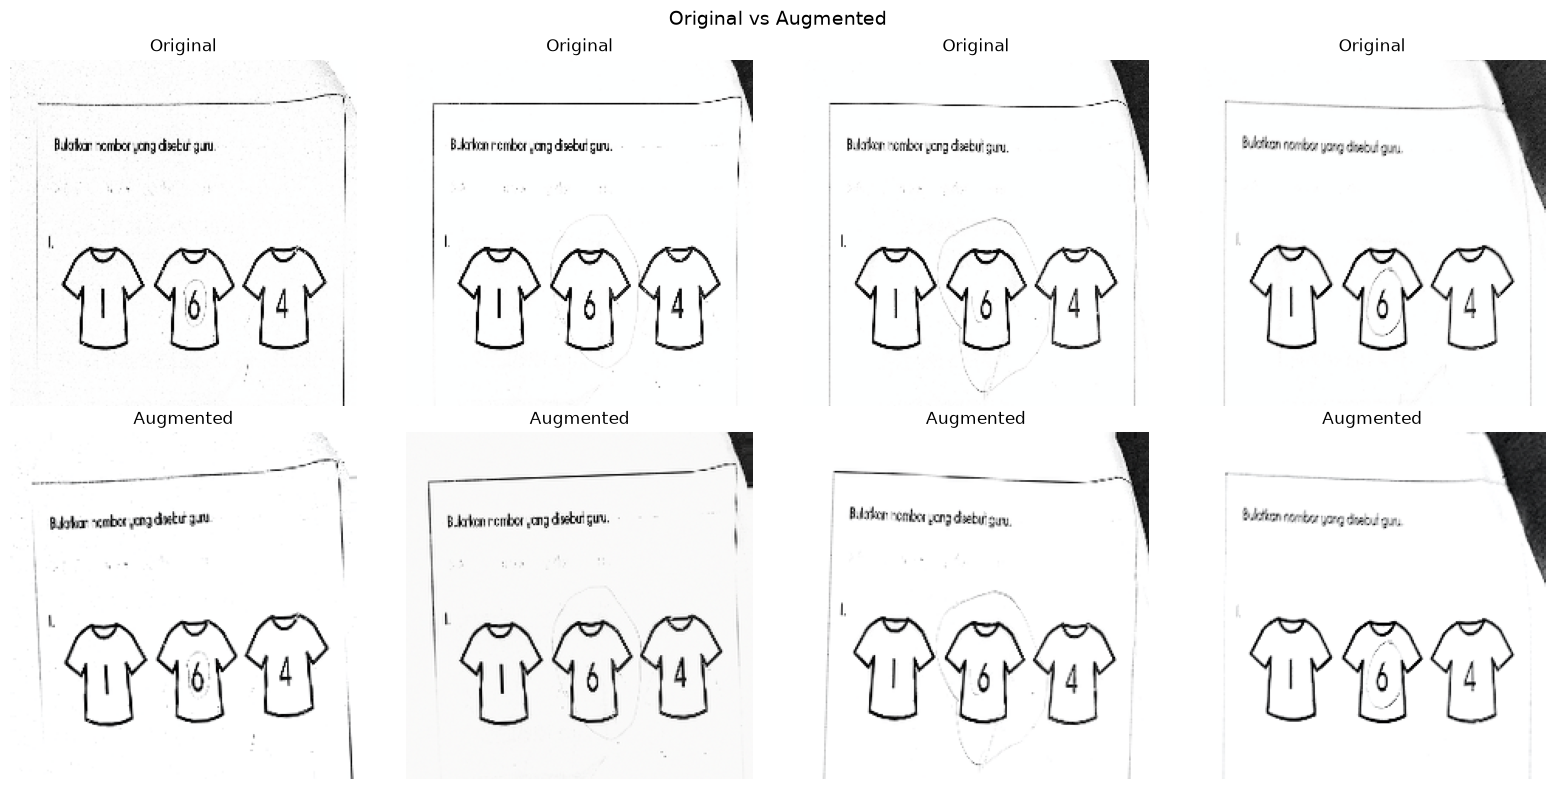

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    axes[0, i].imshow(denormalize_for_display(X[i]))
    axes[0, i].set_title(f"Original")
    axes[1, i].imshow(denormalize_for_display(augment_image(X[i])))
    axes[1, i].set_title(f"Augmented")
for ax in axes.flat:
    ax.axis('off')
plt.suptitle("Original vs Augmented", fontsize=14)
plt.tight_layout()
plt.show()

### Step 11 - K-Fold cross validation split
With a small dataset, a single train/test split could give biased results. Stratified K-Fold (5 folds) ensures each fold has the same Group A / Group B ratio.

Note: with only 2 students, K-Fold cannot run. This code is ready for when more student copies are added to the dataset.

In [11]:
if len(X) >= 5:
    n_folds = 5
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        print(f"Fold {fold+1}: train={len(X_train)} (A:{np.sum(y_train==1)}, B:{np.sum(y_train==0)}) | "
              f"val={len(X_val)} (A:{np.sum(y_val==1)}, B:{np.sum(y_val==0)})")
else:
    print(f"Only {len(X)} students, K-Fold requires at least 5 students.")

Fold 1: train=108 (A:76, B:32) | val=27 (A:20, B:7)
Fold 2: train=108 (A:77, B:31) | val=27 (A:19, B:8)
Fold 3: train=108 (A:77, B:31) | val=27 (A:19, B:8)
Fold 4: train=108 (A:77, B:31) | val=27 (A:19, B:8)
Fold 5: train=108 (A:77, B:31) | val=27 (A:19, B:8)


### Step 12 - Save preprocessed dataset
Save to .npy files so we don't have to redo preprocessing every time.

In [12]:
np.save("../data/processed/X_exercise.npy", X)
np.save("../data/processed/y_exercise.npy", y)
print(f"Saved: X={X.shape}, y={y.shape}")
print(f"File size X: {os.path.getsize('../data/processed/X_exercise.npy') / 1e6:.1f} MB")
print(f"File size y: {os.path.getsize('../data/processed/y_exercise.npy') / 1e6:.1f} MB")

Saved: X=(135, 224, 224, 3), y=(135,)
File size X: 81.3 MB
File size y: 0.0 MB
